# 10. Типы травм по месяцам: какой тип преобладает в каком месяце

Данные: `OSHA_db`, 105 996 тяжёлых травм (январь 2015 – ноябрь 2025). SQL-запрос — `SQL/06_nature.sql` (6.4).

Тип травмы — укрупнённая категория характера травмы (Nature) из раздела 6: переломы, ампутации, ожоги, тепловой удар и т. д. Правила те же, что в SQL (`src/labels.py`, `NATURE_CATEGORIES`).

«Преобладающий тип» можно понимать двумя способами, и ответы на них разные:
- **по числу случаев** — какая категория встречается в месяце чаще всех (доля среди травм месяца) — 10.1;
- **характерный для месяца** — какая категория встречается в этом месяце заметно чаще, чем обычно. Индекс = доля категории в месяце / её доля за весь период × 100 (100 — как обычно). Значимость — скорректированные стандартизованные остатки χ² с поправкой Бонферрони на все 144 ячейки — 10.3.

Дополнительно: сезонный профиль каждой категории в случаях за день, как в разделе 4.8 (10.2), и проверка устойчивости на сопоставимом периоде 2016–2023 (10.4).

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from src.db import query
from src.viz import set_style, tr, finish, LANGS, TABLES_DIR, SERIES
from src.stats import num, cramers_v
from src.labels import nature_category, NATURE_CATEGORIES, NATURE_OTHER, MONTHS, SEASONS, MONTH_TO_SEASON

set_style()
TABLES_DIR.mkdir(exist_ok=True)

SEASON_COLORS = {"winter": SERIES[0], "spring": SERIES[2], "summer": SERIES[1], "autumn": SERIES[3]}
CAT_EN = {ru: en for ru, en, _ in NATURE_CATEGORIES} | {NATURE_OTHER[0]: NATURE_OTHER[1]}

## 10.0. Исходные данные

In [2]:
cases = query("""
    SELECT i.id,
           i.event_date,
           n.title AS nature
    FROM injuries i
    JOIN nature_lookup n ON n.code = i.nature_code
""")
cases["event_date"] = pd.to_datetime(cases["event_date"])
cases["year"] = cases["event_date"].dt.year
cases["month"] = cases["event_date"].dt.month
cases["season"] = cases["month"].map(MONTH_TO_SEASON)
cases["category"] = cases["nature"].map(lambda t: nature_category(t)[0])

# календарь периода наблюдения: месяцы разной длины, декабря 2025 года в данных нет
days = pd.DataFrame({"date": pd.date_range(cases["event_date"].min(), cases["event_date"].max(), freq="D")})
days["month"] = days["date"].dt.month

N = len(cases)
ORDER = cases["category"].value_counts().index.tolist()  # категории по убыванию числа случаев
print(f"Случаев: {num(N)}, период: {cases['event_date'].min():%d.%m.%Y} – {cases['event_date'].max():%d.%m.%Y}")
cases["category"].value_counts().rename("cases").to_frame()

Случаев: 105 996, период: 01.01.2015 – 30.11.2025


,cases
category,
Переломы,38359
Ампутации,28685
Прочее,8163
"Раны (порезы, проколы)",6715
Боль без уточнения,6538
Ожоги,5991
Черепно-мозговые травмы,3476
Тепловой удар / перегрев,2658
Размозжения,2039


In [3]:
CRIT = stats.norm.ppf(1 - 0.05 / 2 / (len(ORDER) * 12))  # Бонферрони: 12 категорий × 12 месяцев


def month_mix(df):
    """Категория × месяц: число случаев, доля в месяце, индекс к обычной доле, скорректированные остатки χ²."""
    counts = pd.crosstab(df["category"], df["month"]).reindex(ORDER).fillna(0).astype(int)
    n = counts.to_numpy().sum()
    share = 100 * counts / counts.sum()
    share_all = 100 * counts.sum(axis=1) / n
    chi2, p, dof, v, expected = cramers_v(counts)
    row = counts.sum(axis=1).to_numpy()[:, None] / n
    col = counts.sum(axis=0).to_numpy()[None, :] / n
    return {
        "counts": counts,
        "share": share,
        "share_all": share_all,
        "index": 100 * share.div(share_all, axis=0),
        "resid": (counts - expected) / np.sqrt(expected * (1 - row) * (1 - col)),
        "chi2": chi2, "p": p, "dof": dof, "v": v,
    }


def characteristic(mix, month):
    """Категории, которые в этом месяце значимо чаще обычного, — по убыванию индекса."""
    sig = mix["resid"].index[mix["resid"][month] > CRIT]
    return mix["index"].loc[sig, month].sort_values(ascending=False)


mix = month_mix(cases)
print(f"Порог значимости остатка (Бонферрони, {len(ORDER) * 12} ячеек): r > {CRIT:.2f}")

Порог значимости остатка (Бонферрони, 144 ячеек): r > 3.58


## 10.1. Состав травм по месяцам: какой тип встречается чаще всех

Доля каждой категории среди всех тяжёлых травм месяца (по столбцу сумма 100%).

In [4]:
share = mix["share"]
mix["counts"].to_csv(TABLES_DIR / "10_1_category_month_counts.csv", encoding="utf-8-sig")
share.round(2).assign(all_months=mix["share_all"].round(2)).to_csv(
    TABLES_DIR / "10_1_category_month_share.csv", encoding="utf-8-sig")

leader = share.idxmax()
for m in share.columns:
    first, second = share[m].nlargest(2).index
    print(f"{MONTHS[m][0]}: {first} {share.loc[first, m]:.1f}%, затем {second} {share.loc[second, m]:.1f}%")
share.round(1).set_axis([MONTHS[m][0] for m in share.columns], axis=1)

Янв: Переломы 39.2%, затем Ампутации 25.9%
Фев: Переломы 39.2%, затем Ампутации 26.8%
Мар: Переломы 37.0%, затем Ампутации 27.8%
Апр: Переломы 36.0%, затем Ампутации 27.5%
Май: Переломы 34.9%, затем Ампутации 27.7%
Июн: Переломы 33.7%, затем Ампутации 26.7%
Июл: Переломы 32.4%, затем Ампутации 24.5%
Авг: Переломы 33.8%, затем Ампутации 25.8%
Сен: Переломы 35.5%, затем Ампутации 27.4%
Окт: Переломы 36.1%, затем Ампутации 29.5%
Ноя: Переломы 39.0%, затем Ампутации 28.1%
Дек: Переломы 39.1%, затем Ампутации 27.6%


,Янв,Фев,Мар,Апр,Май,Июн,Июл,Авг,Сен,Окт,Ноя,Дек
category,,,,,,,,,,,,
Переломы,39.2,39.2,37.0,36.0,34.9,33.7,32.4,33.8,35.5,36.1,39.0,39.1
Ампутации,25.9,26.8,27.8,27.5,27.7,26.7,24.5,25.8,27.4,29.5,28.1,27.6
Прочее,8.2,7.8,7.8,8.2,8.0,8.0,7.2,7.7,7.6,7.2,7.1,7.5
"Раны (порезы, проколы)",5.4,5.5,6.0,7.0,7.0,6.9,6.6,6.9,6.5,6.2,6.1,5.8
Боль без уточнения,6.5,6.8,7.0,6.4,6.2,5.6,6.0,5.3,5.8,6.2,5.7,6.8
Ожоги,5.9,5.0,5.4,5.8,5.7,5.9,5.9,5.7,5.8,5.7,5.7,5.2
Черепно-мозговые травмы,4.0,3.9,3.7,3.3,3.1,2.7,2.7,3.0,3.3,3.3,3.2,3.4
Тепловой удар / перегрев,0.1,0.1,0.2,0.4,1.8,5.6,9.5,6.4,2.9,0.6,0.2,0.1
Размозжения,1.9,1.9,2.2,2.0,2.2,1.8,1.9,2.0,1.8,1.9,1.8,1.6


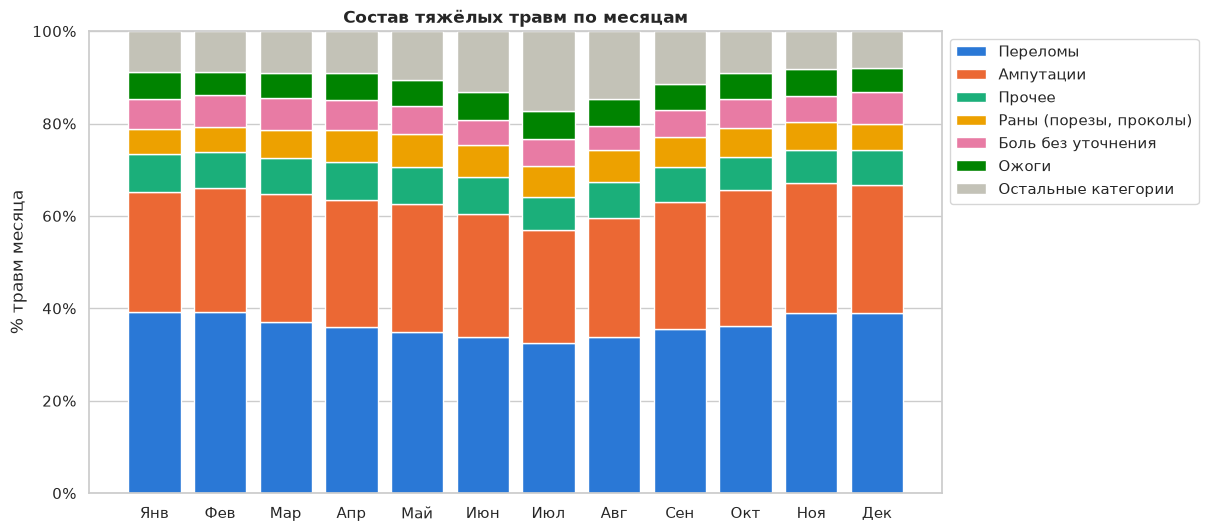

In [5]:
main = ORDER[:6]
comp = share.loc[main].copy()
comp.loc["rest"] = 100 - comp.sum()

for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(11, 6))
    bottom = np.zeros(12)
    labels = [tr(c, CAT_EN[c], lang) for c in main] + [tr("Остальные категории", "Other categories", lang)]
    for (_, row), color, label in zip(comp.iterrows(), SERIES[:6] + ["#c3c2b7"], labels):
        ax.bar(comp.columns, row, bottom=bottom, color=color, label=label, edgecolor="white", linewidth=1)
        bottom += row.to_numpy()
    ax.set_xticks(range(1, 13), [MONTHS[m][k] for m in range(1, 13)])
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_ylim(0, 100)
    ax.set_title(tr("Состав тяжёлых травм по месяцам", "Composition of severe injuries by month", lang))
    ax.set_ylabel(tr("% травм месяца", "% of the month's injuries", lang))
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    ax.grid(axis="x", visible=False)
    finish(fig, "10_1_month_composition", lang)

## 10.2. Сезонный профиль каждой категории

Среднее число случаев в день по месяцам (месяцы разной длины, декабря 2025 года нет), индекс — к среднему для этой категории (100 = обычный месяц). Этот профиль включает и общую сезонность: летом всех травм больше (раздел 4).

In [6]:
month_days = days.groupby("month").size()
rate = mix["counts"].div(month_days, axis=1)
rate_idx = 100 * rate.div(rate.mean(axis=1), axis=0)

peaks = pd.DataFrame({
    "category_en": [CAT_EN[c] for c in ORDER],
    "cases": mix["counts"].sum(axis=1),
    "peak_month": rate.idxmax(axis=1),
    "peak_index": rate_idx.max(axis=1),
    "low_month": rate.idxmin(axis=1),
    "low_index": rate_idx.min(axis=1),
    "summer_share": [100 * cases.loc[cases["category"] == c, "season"].eq("summer").mean() for c in ORDER],
    "winter_share": [100 * cases.loc[cases["category"] == c, "season"].eq("winter").mean() for c in ORDER],
}, index=pd.Index(ORDER, name="category_ru"))
peaks.insert(3, "peak_month_ru", peaks["peak_month"].map(lambda m: MONTHS[m][0]))
peaks.insert(6, "low_month_ru", peaks["low_month"].map(lambda m: MONTHS[m][0]))

rate_idx.round(1).to_csv(TABLES_DIR / "10_2_category_rate_index.csv", encoding="utf-8-sig")
peaks.round(1).to_csv(TABLES_DIR / "10_2_category_peaks.csv", encoding="utf-8-sig")
print(f"Равномерное распределение по сезонам — около 25% на сезон")
peaks.round(1)

Равномерное распределение по сезонам — около 25% на сезон


,category_en,cases,peak_month,peak_month_ru,peak_index,low_month,low_month_ru,low_index,summer_share,winter_share
category_ru,,,,,,,,,,
Переломы,Fractures,38359,2,Фев,111.5,5,Май,92.5,25.4,25.1
Ампутации,Amputations,28685,10,Окт,109.3,12,Дек,89.0,26.1,23.0
Прочее,Other,8163,6,Июн,113.0,12,Дек,84.8,27.4,23.7
"Раны (порезы, проколы)","Wounds (cuts, punctures)",6715,6,Июн,117.9,12,Дек,80.0,29.5,20.4
Боль без уточнения,Unspecified pain,6538,2,Фев,113.7,11,Ноя,85.6,25.2,25.3
Ожоги,Burns,5991,7,Июл,114.8,12,Дек,79.6,28.5,22.0
Черепно-мозговые травмы,Brain injuries,3476,2,Фев,121.7,7,Июл,88.1,23.3,26.6
Тепловой удар / перегрев,Heat illness,2658,7,Июл,421.1,12,Дек,2.0,79.0,0.6
Размозжения,Crushing injuries,2039,3,Мар,111.5,12,Дек,74.0,27.0,22.1


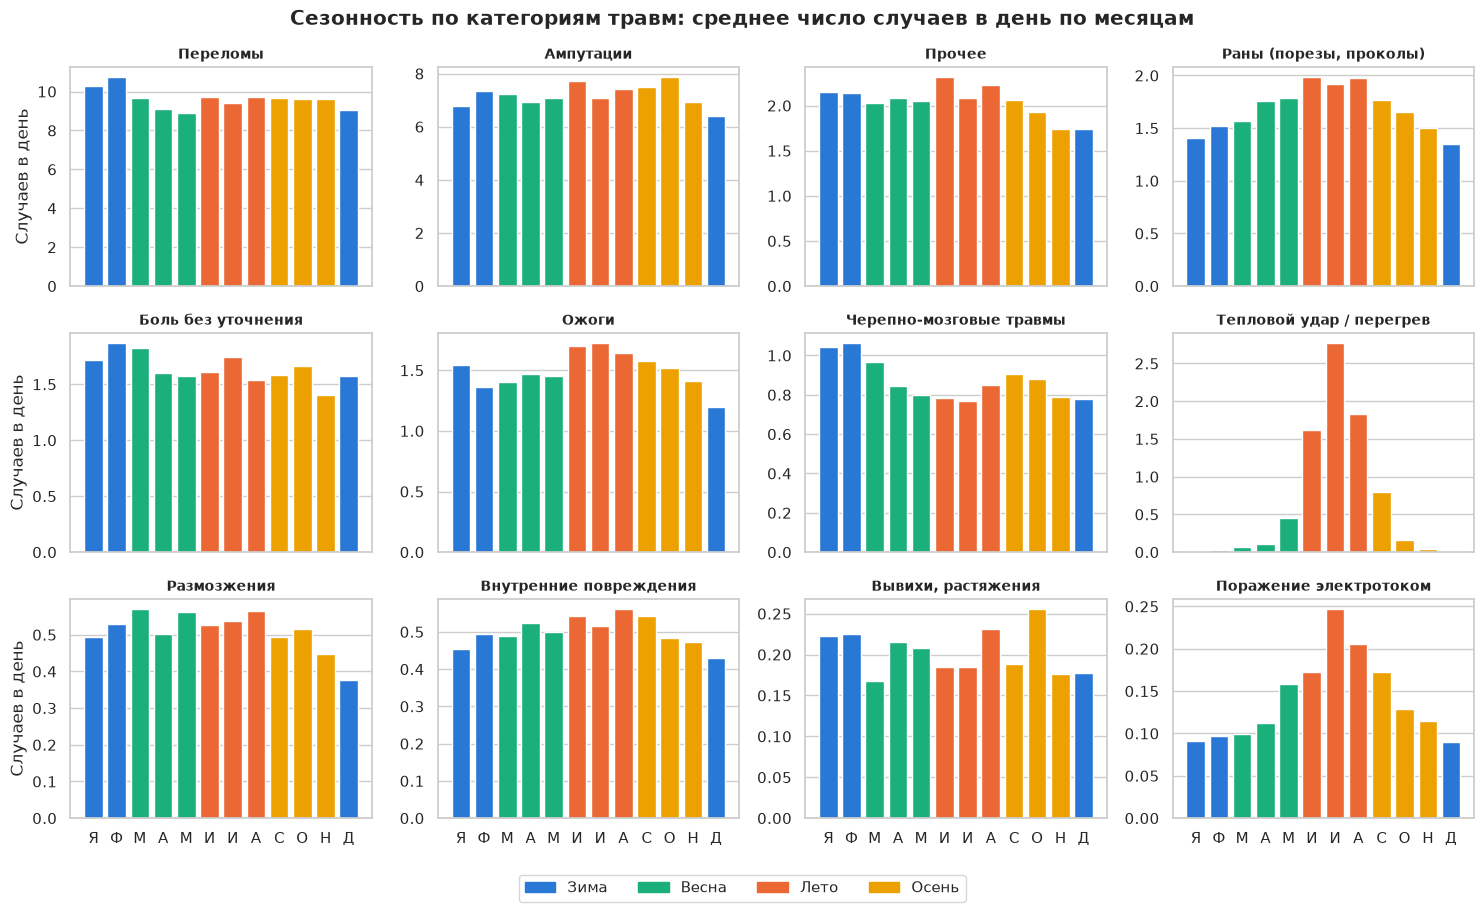

In [7]:
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, axes = plt.subplots(3, 4, figsize=(15, 9), sharex=True)
    for ax, c in zip(axes.flat, ORDER):
        s = rate.loc[c]
        ax.bar(s.index, s, color=[SEASON_COLORS[MONTH_TO_SEASON[m]] for m in s.index])
        ax.set_title(tr(c, CAT_EN[c], lang), fontsize=10)
        ax.set_xticks(range(1, 13), [MONTHS[m][k][0] for m in range(1, 13)])
        ax.grid(axis="x", visible=False)
    for ax in axes[:, 0]:
        ax.set_ylabel(tr("Случаев в день", "Cases per day", lang))
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in SEASON_COLORS.values()],
               labels=[SEASONS[s][k] for s in SEASON_COLORS], loc="lower center", ncols=4,
               bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(tr("Сезонность по категориям травм: среднее число случаев в день по месяцам",
                    "Seasonality by injury category: average cases per day by month", lang), fontweight="bold")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    finish(fig, "10_2_category_seasonality", lang)

## 10.3. Какой тип травм характерен для каждого месяца

Индекс = доля категории среди травм месяца / её доля за весь период × 100. Индекс 381 означает, что в этом месяце доля категории в 3,8 раза выше обычной. Общая сезонность (летом травм больше) в индексе не участвует: сравнивается только состав.

Ячейка считается значимой, если скорректированный стандартизованный остаток больше порога Бонферрони. Характерная категория месяца — значимая категория с наибольшим индексом. Если значимых нет, состав месяца обычный.

In [8]:
print(f"Категория травмы × месяц: χ² = {num(mix['chi2'])}, df = {mix['dof']}, p = {mix['p']:.2e}, "
      f"V Крамера = {mix['v']:.3f}")

rows = []
for m in mix["counts"].columns:
    ch = characteristic(mix, m)
    rows.append({
        "month": m,
        "month_ru": MONTHS[m][0],
        "cases": mix["counts"][m].sum(),
        "leader": share[m].idxmax(),
        "leader_pct": share[m].max(),
        "characteristic": ch.index[0] if len(ch) else None,
        "char_index": ch.iloc[0] if len(ch) else None,
        "char_resid": mix["resid"].loc[ch.index[0], m] if len(ch) else None,
        "also": ", ".join(f"{c} ({i:.0f})" for c, i in ch.iloc[1:].items()) or None,
    })
leaders = pd.DataFrame(rows).set_index("month")

mix["index"].round(1).to_csv(TABLES_DIR / "10_3_category_month_index.csv", encoding="utf-8-sig")
mix["resid"].round(2).to_csv(TABLES_DIR / "10_3_category_month_resid.csv", encoding="utf-8-sig")
leaders.round(2).to_csv(TABLES_DIR / "10_3_month_leaders.csv", encoding="utf-8-sig")
leaders.round(1)

Категория травмы × месяц: χ² = 4 621, df = 121, p = 0.00e+00, V Крамера = 0.063


,month_ru,cases,leader,leader_pct,characteristic,char_index,char_resid,also
month,,,,,,,,
1,Янв,8935,Переломы,39.2,Черепно-мозговые травмы,121.2,3.8,Переломы (108)
2,Фев,8516,Переломы,39.2,Переломы,108.2,6.0,NaN
3,Мар,8890,Переломы,37.0,NaN,NaN,NaN,NaN
4,Апр,8328,Переломы,36.0,NaN,NaN,NaN,NaN
5,Май,8703,Переломы,34.9,NaN,NaN,NaN,NaN
6,Июн,9527,Переломы,33.7,Тепловой удар / перегрев,223.5,20.3,NaN
7,Июл,9875,Переломы,32.4,Тепловой удар / перегрев,380.8,47.0,Поражение электротоком (160)
8,Авг,9821,Переломы,33.8,Тепловой удар / перегрев,253.4,25.6,NaN
9,Сен,8994,Переломы,35.5,NaN,NaN,NaN,NaN


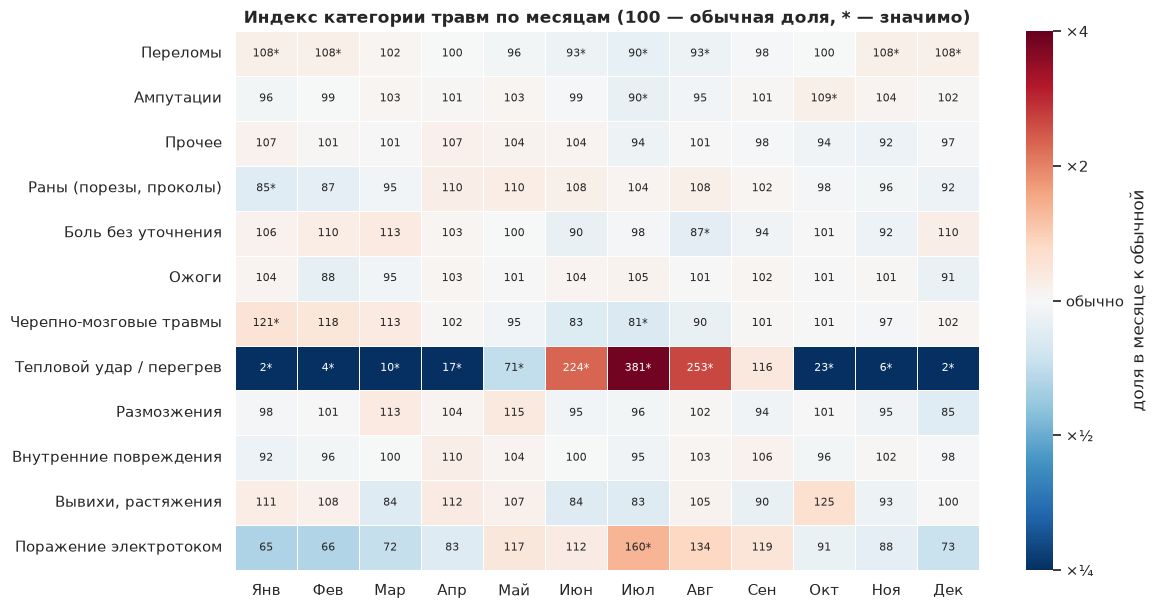

In [9]:
log_ratio = np.log2(mix["index"] / 100).clip(-2, 2)
stars = np.where(mix["resid"].abs() > CRIT, "*", "")
annot = mix["index"].round(0).astype(int).astype(str) + stars

for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(12, 7))
    sns.heatmap(log_ratio, annot=annot, fmt="", cmap="RdBu_r", center=0, vmin=-2, vmax=2,
                linewidths=0.5, linecolor="white", annot_kws={"fontsize": 8}, ax=ax,
                xticklabels=[MONTHS[m][k] for m in log_ratio.columns],
                yticklabels=[tr(c, CAT_EN[c], lang) for c in log_ratio.index],
                cbar_kws={"label": tr("доля в месяце к обычной", "share in month vs usual", lang),
                          "ticks": [-2, -1, 0, 1, 2]})
    ax.collections[0].colorbar.set_ticklabels(["×¼", "×½", tr("обычно", "usual", lang), "×2", "×4"])
    ax.set_title(tr("Индекс категории травм по месяцам (100 — обычная доля, * — значимо)",
                    "Injury category index by month (100 = usual share, * = significant)", lang))
    ax.set_xlabel("")
    ax.set_ylabel("")
    finish(fig, "10_3_category_month_index", lang)

## 10.4. Проверка устойчивости: сопоставимый период 2016–2023

В 2015 году завышены «Прочее» и «Боль без уточнения», с 2024 года действует новая редакция OIICS, а декабря 2025 года в данных нет. Повторяем расчёт на полных годах с одной редакцией классификации.

In [10]:
mix2 = month_mix(cases[cases["year"].between(2016, 2023)])
print(f"2016–2023: χ² = {num(mix2['chi2'])}, p = {mix2['p']:.2e}, V Крамера = {mix2['v']:.3f}")

robust = pd.DataFrame({
    "month_ru": leaders["month_ru"],
    "all_years": leaders["characteristic"],
    "all_years_index": leaders["char_index"],
    "y2016_2023": [characteristic(mix2, m).index[0] if len(characteristic(mix2, m)) else None for m in leaders.index],
    "y2016_2023_index": [characteristic(mix2, m).iloc[0] if len(characteristic(mix2, m)) else None for m in leaders.index],
})
robust["same"] = robust["all_years"].fillna("—") == robust["y2016_2023"].fillna("—")
robust.round(1).to_csv(TABLES_DIR / "10_4_robustness.csv", encoding="utf-8-sig")
print(f"Характерная категория совпадает в {robust['same'].sum()} из 12 месяцев")
robust.round(1)

2016–2023: χ² = 3 405, p = 0.00e+00, V Крамера = 0.063
Характерная категория совпадает в 12 из 12 месяцев


,month_ru,all_years,all_years_index,y2016_2023,y2016_2023_index,same
month,,,,,,
1,Янв,Черепно-мозговые травмы,121.2,Черепно-мозговые травмы,131.0,True
2,Фев,Переломы,108.2,Переломы,108.6,True
3,Мар,NaN,NaN,NaN,NaN,True
4,Апр,NaN,NaN,NaN,NaN,True
5,Май,NaN,NaN,NaN,NaN,True
6,Июн,Тепловой удар / перегрев,223.5,Тепловой удар / перегрев,226.7,True
7,Июл,Тепловой удар / перегрев,380.8,Тепловой удар / перегрев,360.8,True
8,Авг,Тепловой удар / перегрев,253.4,Тепловой удар / перегрев,266.7,True
9,Сен,NaN,NaN,NaN,NaN,True


## Выводы

1. **По числу случаев во всех 12 месяцах преобладают переломы**: от 32,4% травм месяца в июле до 39,2% в январе и феврале. На втором месте всегда ампутации (24,5–29,5%). В этом смысле главный тип тяжёлой травмы от месяца не зависит.
2. **Состав травм по месяцам меняется мало**: χ² = 4 621, df = 121, p < 0,001, но V Крамера = 0,063 (связь слабая). Кроме теплового удара и электротравмы, индексы категорий держатся в пределах 80–125.
3. **Характерный тип травмы есть не у каждого месяца** (значимо чаще обычного, порог Бонферрони):
   - **лето — тепловой удар / перегрев.** Его доля в июне в 2,2 раза выше обычной, в июле в 3,8, в августе в 2,5 раза. 79% всех тепловых ударов приходится на лето, в июле их в день в 4,2 раза больше, чем в среднем за год. В июле также чаще поражение электротоком (индекс 160, 37% таких случаев летом);
   - **зима (ноябрь–февраль) — переломы** (индекс 108), **в январе — черепно-мозговые травмы** (121). Это согласуется с зимним пиком падений на одном уровне и травм, связанных со льдом и снегом (раздел 4.8);
   - **октябрь — ампутации**: 29,5% травм месяца, максимум за год (индекс 109);
   - **март–май и сентябрь** — значимо выделяющихся категорий нет, состав травм обычный.
4. **Обратная сторона сезонности.** Летом ниже доли переломов (июль — 90) и черепно-мозговых травм (81), в январе ниже доля ран (85). Тепловой удар с октября по апрель почти не встречается (индекс 2–23), но уже в мае его доля растёт (71), а в июне превышает обычную вдвое.
5. **Результат устойчив.** На сопоставимом периоде 2016–2023 (полные годы, одна редакция OIICS) характерная категория совпала во всех 12 месяцах: тепловой удар в июле — индекс 361, черепно-мозговые травмы в январе — 131.

Для календаря профилактики это значит: защиту от жары (вода, тень, отдых, акклиматизация) стоит начинать в мае, до июньского роста; меры против поскальзывания и падений — к ноябрю; в октябре — проверку защитных ограждений оборудования, когда доля ампутаций максимальна.
